# Global 90/60: Simple NTSG-Inspired Simulation

## Objective

Compare a monthly synthetic 90/60 model with official NTSG USD NAV, then compare it with world equities and a 60/40 portfolio. This is not a reconstruction of NTSG's holdings, bond futures or historical performance.

## Monthly model

Use USD world-equity and unhedged government-bond total-return indices. Reset exposures at month-end in February, May, August and November; weights drift between resets. At a reset:

$$
R_{90/60,t}=0.90R_{E,t}+0.60R_{B,t}-0.50R_{f,t}-C_t.
$$

This approximates the bond overlay as $R_B-R_f$ per unit of notional and assumes 10% of NAV earns USD cash. It is a funded-bond financing approximation, not actual futures P&L. The bond index's country, currency, duration and composition differ from NTSG's futures and collateral. Do not subtract a second financing charge.

| Input | Local data | Limitation |
| --- | --- | --- |
| Equities | [MSCI World net total return USD](data/MSCI_WORLD_NET_USD_MONTHLY.CSV) | Not NTSG's screened equity selection. |
| Bonds | [FTSE WGBI developed USD unhedged](data/FTSE_WGBI_DM_USD_UNHEDGED_MONTHLY.CSV) | Cash bonds, not futures or USD-hedged exposure. |
| Cash | [Kenneth French USD bill return](data/FRENCH_USD_BILL_MONTHLY.CSV) | Bill return, not actual funding or multicurrency collateral. |
| NTSG | [Official USD accumulating NAV](data/NTSG_NAV_USD_WISDOMTREE.CSV) | Net of fund costs; not the benchmark index. |

The long-history panel uses complete common monthly returns. Source details and limitations are in the [data manifest](data/90_60_alternative_sources_manifest.json) and [supplemental research](insights/pareto_superiority_90_60.md).

## Fees, implementation drag and validation

Deduct the current 0.25% annual fund expense from the synthetic model only. The official accumulating NAV is already net of fund costs; do not deduct it again. Additional futures basis, roll and execution effects are unknown. The base case assumes zero additional drag; positive drag is an explicit sensitivity per unit of bond notional, not a measured NTSG cost. No adjustment is fitted to the NAV overlap.

The NAV comparison uses the last available observations in each calendar month. Actual observation dates are displayed: holidays, market closing times and pricing conventions can differ. A short overlap cannot validate long-run replication.


## Validation of the uncalibrated proxy against official NTSG NAV


In [6]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore", message="Sorting by default when concatenating all DatetimeIndex is deprecated.*")
DATA = Path("data")


def load_prices(filename):
    prices = pd.read_csv(DATA / filename, parse_dates=["date"])
    prices = prices.set_index("date")["adjusted_price"].sort_index()
    if prices.index.has_duplicates or prices.isna().any() or not np.isfinite(prices).all() or (prices <= 0).any():
        raise ValueError(f"Invalid prices in {filename}")
    return prices


def quarterly_returns(data, equity_weight, bond_weight, monthly_fee=0.0, annual_drag=0.0):
    equity = 1000.0 * equity_weight
    bond = 1000.0 * bond_weight
    cash = 1000.0 - equity - bond
    monthly_returns = []
    for date, row in data.iterrows():
        start_nav = equity + bond + cash
        if start_nav <= 0:
            raise ValueError("Portfolio NAV must remain positive")
        fee = start_nav * monthly_fee + bond * annual_drag / 12
        equity *= 1 + row["equity"]
        bond *= 1 + row["bond"]
        cash = cash * (1 + row["risk_free"]) - fee
        nav = equity + bond + cash
        if nav <= 0:
            raise ValueError("Portfolio NAV must remain positive")
        monthly_returns.append(nav / start_nav - 1)
        if date.month in (2, 5, 8, 11):
            equity = nav * equity_weight
            bond = nav * bond_weight
            cash = nav - equity - bond
    return pd.Series(monthly_returns, index=data.index)


levels = pd.concat({
    "equity": load_prices("MSCI_WORLD_NET_USD_MONTHLY.CSV"),
    "bond": load_prices("FTSE_WGBI_DM_USD_UNHEDGED_MONTHLY.CSV"),
    "risk_free": load_prices("FRENCH_USD_BILL_MONTHLY.CSV"),
}, axis=1, sort=True)
start = max(levels[column].first_valid_index() for column in levels)
end = min(levels[column].last_valid_index() for column in levels)
levels = levels.reindex(pd.date_range(start, end, freq="ME"))
if levels.isna().any().any():
    raise ValueError("Missing monthly index levels in the common history")
returns = levels.pct_change(fill_method=None).dropna()
fund_cost = 1 - (1 - 0.0025) ** (1 / 12)

nav_prices = load_prices("NTSG_NAV_USD_WISDOMTREE.CSV")
nav_monthly = nav_prices.resample("ME").last()
nav_observation_dates = pd.Series(nav_prices.index, index=nav_prices.index).resample("ME").last()
if pd.Timestamp.today().normalize() <= nav_monthly.index[-1]:
    nav_monthly = nav_monthly.iloc[:-1]
    nav_observation_dates = nav_observation_dates.iloc[:-1]
nav_returns = nav_monthly.pct_change(fill_method=None).rename("NTSG_NAV")
proxy_returns = quarterly_returns(returns, 0.90, 0.60, fund_cost).rename("NTSG_proxy")
comparison = pd.concat([proxy_returns, nav_returns], axis=1).dropna()
if comparison.empty or not comparison.index.equals(pd.date_range(comparison.index[0], comparison.index[-1], freq="ME")):
    raise ValueError("Missing or non-contiguous NAV comparison returns")
difference = comparison["NTSG_proxy"] - comparison["NTSG_NAV"]
wealth = (1 + comparison).cumprod()
print(f"NAV comparison: {comparison.index[0]:%Y-%m} to {comparison.index[-1]:%Y-%m} ({len(comparison)} months)")
print(f"Monthly correlation: {comparison.corr().iloc[0, 1]:.4f}")
print(f"Annualized tracking error: {difference.std(ddof=1) * 12 ** 0.5:.2%}")
print(f"Monthly return RMSE: {difference.pow(2).mean() ** 0.5:.2%}")
print("NAV already includes fund expenses; the proxy is uncalibrated.")
display(pd.DataFrame({
    "NAV observation date": nav_observation_dates.reindex(comparison.index),
    "Proxy monthly return": comparison["NTSG_proxy"],
    "NAV monthly return": comparison["NTSG_NAV"],
    "Proxy growth": wealth["NTSG_proxy"],
    "NAV growth": wealth["NTSG_NAV"],
}))


NAV comparison: 2024-12 to 2026-08 (21 months)
Monthly correlation: 0.9902
Annualized tracking error: 1.75%
Monthly return RMSE: 0.49%
NAV already includes fund expenses; the proxy is uncalibrated.


,NAV observation date,Proxy monthly return,NAV monthly return,Proxy growth,NAV growth
2024-12-31,2024-12-31,-0.039437,-0.039329,0.960563,0.960671
2025-01-31,2025-01-31,0.030411,0.034622,0.989775,0.993932
2025-02-28,2025-02-28,0.002088,0.006955,0.991841,1.000845
2025-03-31,2025-03-31,-0.037627,-0.042481,0.954521,0.958329
2025-04-30,2025-04-30,0.027882,0.020107,0.981135,0.977597
2025-05-31,2025-05-30,0.043325,0.040894,1.023643,1.017575
2025-06-30,2025-06-30,0.048410,0.045390,1.073197,1.063763
2025-07-31,2025-07-31,-0.000802,0.001495,1.072337,1.065353
2025-08-31,2025-08-29,0.027433,0.030128,1.101754,1.097450
2025-09-30,2025-09-30,0.032983,0.030583,1.138093,1.131014


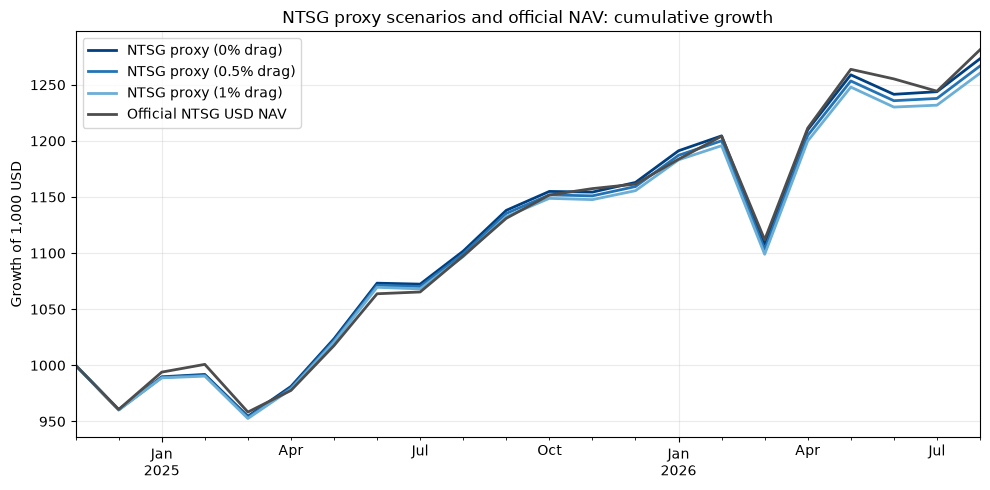

In [7]:
import matplotlib.pyplot as plt

proxy_colors = {
    "NTSG proxy (0% drag)": "#003f80",
    "NTSG proxy (0.5% drag)": "#2474b5",
    "NTSG proxy (1% drag)": "#6baed6",
}
portfolio_colors = {**proxy_colors, "60/40": "#b35806", "100% equities": "#4d4d4d"}
proxy_styles = {"NTSG proxy (0% drag)": "-", "NTSG proxy (0.5% drag)": "-", "NTSG proxy (1% drag)": "-"}
plot_returns = pd.DataFrame({
    f"NTSG proxy ({drag:g}% drag)": quarterly_returns(returns, 0.90, 0.60, fund_cost, drag / 100).loc[comparison.index]
    for drag in (0, 0.5, 1)
})
plot_returns["Official NTSG USD NAV"] = comparison["NTSG_NAV"]
plot_wealth = 1000 * (1 + plot_returns).cumprod()
plot_wealth.loc[plot_wealth.index[0] - pd.offsets.MonthEnd(1)] = 1000
plot_wealth = plot_wealth.sort_index()
ax = plot_wealth.plot(figsize=(10, 5), linewidth=2, color=[*proxy_colors.values(), "#4d4d4d"],
                      style=[*[proxy_styles[column] for column in proxy_colors], "-"])
ax.set_title("NTSG proxy scenarios and official NAV: cumulative growth")
ax.set_xlabel("")
ax.set_ylabel("Growth of 1,000 USD")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


The proxy is not fitted to the NAV comparison. The funded-bond and financing weights drift until the next scheduled reset. NTSG's actual government futures, collateral currencies and exceptional resets are not replicated.


### Comparison of NTSG proxy, 60/40 and stock for the long run

Monthly USD returns: 1985-02 to 2026-08
Proxy includes a 0.25% annual fund fee; extra drag scenarios are annual rates per bond notional, not measured costs.
Benchmarks use annual TERs of 0.10% for equities and 0.05% for bonds.


,NTSG proxy (0% drag),NTSG proxy (0.5% drag),NTSG proxy (1% drag),60/40,100% equities
1985-02-28,-0.009566,-0.009816,-0.010066,-0.004371,0.001623
1985-03-31,0.002737,0.002487,0.002237,0.003964,0.034373
1985-04-30,0.047633,0.047404,0.047176,0.034193,-0.003079
1985-05-31,0.051313,0.051084,0.050855,0.036828,0.051052
1985-06-30,0.026478,0.026228,0.025978,0.019558,0.017508
...,...,...,...,...,...
2026-04-30,0.092384,0.092147,0.091909,0.060866,0.095835
2026-05-31,0.040466,0.040242,0.040018,0.028064,0.045438
2026-06-30,-0.013784,-0.014034,-0.014284,-0.008150,-0.007259
2026-07-31,0.001875,0.001624,0.001372,0.002427,0.005048


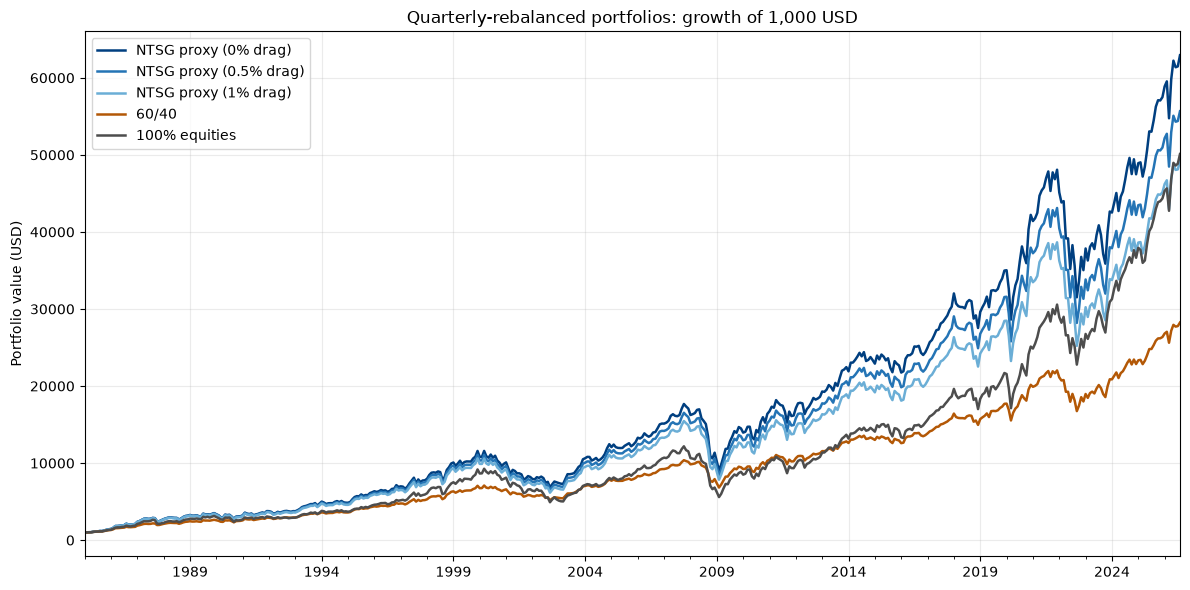

In [8]:
equity_ter = 1 - (1 - 0.0010) ** (1 / 12)
bond_ter = 1 - (1 - 0.0005) ** (1 / 12)
equity_net = returns["equity"] - equity_ter
bond_net = returns["bond"] - bond_ter
benchmark_inputs = returns.assign(equity=equity_net, bond=bond_net)
portfolio_returns = pd.DataFrame({
    **{
        f"NTSG proxy ({drag:g}% drag)": quarterly_returns(returns, 0.90, 0.60, fund_cost, drag / 100)
        for drag in (0, 0.5, 1)
    },
    "60/40": quarterly_returns(benchmark_inputs, 0.60, 0.40),
    "100% equities": equity_net,
})
initial_date = portfolio_returns.index[0] - pd.offsets.MonthEnd(1)
portfolio_values = 1000 * (1 + portfolio_returns).cumprod()
portfolio_values.loc[initial_date] = 1000
portfolio_values = portfolio_values.sort_index()

print(f"Monthly USD returns: {portfolio_returns.index[0]:%Y-%m} to {portfolio_returns.index[-1]:%Y-%m}")
print("Proxy includes a 0.25% annual fund fee; extra drag scenarios are annual rates per bond notional, not measured costs.")
print("Benchmarks use annual TERs of 0.10% for equities and 0.05% for bonds.")
display(portfolio_returns)

ax = portfolio_values.plot(figsize=(12, 6), linewidth=1.8, color=[portfolio_colors[column] for column in portfolio_values],
                           style=[proxy_styles.get(column, "-") for column in portfolio_values])
ax.set_title("Quarterly-rebalanced portfolios: growth of 1,000 USD")
ax.set_xlabel("")
ax.set_ylabel("Portfolio value (USD)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


Average drawdown is the mean of each episode’s maximum loss, including ongoing episodes.
Sharpe and Sortino use monthly USD bill returns; Sortino downside is relative to the monthly bill return.


,Total return,CAGR,Volatility,Max drawdown,Average drawdown,Sharpe,Sortino,Calmar
NTSG proxy (0% drag),6193.64%,10.47%,15.31%,-48.81%,-6.77%,0.52,0.79,0.21
NTSG proxy (0.5% drag),5466.37%,10.15%,15.32%,-49.05%,-6.84%,0.50,0.76,0.21
NTSG proxy (1% drag),4822.70%,9.82%,15.32%,-49.28%,-6.79%,0.49,0.72,0.20
60/40,2724.45%,8.37%,10.20%,-34.20%,-4.51%,0.53,0.80,0.24
100% equities,4911.17%,9.87%,15.09%,-54.09%,-6.63%,0.49,0.72,0.18


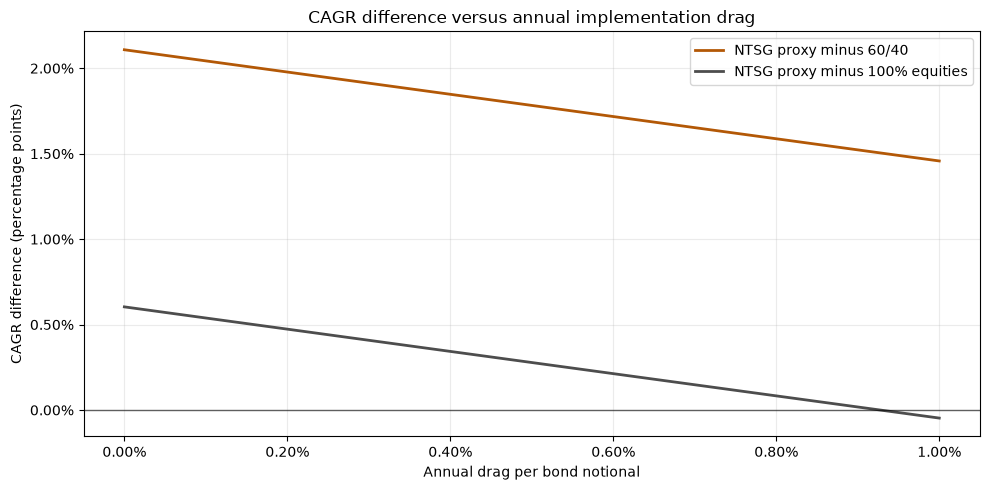

In [9]:
wealth_history = (1 + portfolio_returns).cumprod()
initial_date = portfolio_returns.index[0] - pd.offsets.MonthEnd(1)
wealth_history.loc[initial_date] = 1.0
wealth_history = wealth_history.sort_index()
total_return = wealth_history.iloc[-1] - 1
cagr = (1 + total_return) ** (12 / len(portfolio_returns)) - 1
volatility = portfolio_returns.std(ddof=1) * 12 ** 0.5
drawdown_history = wealth_history / wealth_history.cummax() - 1
max_drawdown = drawdown_history.min()
average_drawdown = pd.Series({
    column: series[series < 0].groupby(series.eq(0).cumsum()).min().mean()
    for column, series in drawdown_history.items()
})
excess_returns = portfolio_returns.sub(returns["risk_free"], axis=0)
excess_volatility = excess_returns.std(ddof=1).replace(0, float("nan"))
downside_deviation = (excess_returns.clip(upper=0).pow(2).mean() ** 0.5).replace(0, float("nan"))
sharpe = excess_returns.mean() / excess_volatility * 12 ** 0.5
sortino = excess_returns.mean() / downside_deviation * 12 ** 0.5
calmar = cagr / (-max_drawdown).replace(0, float("nan"))

summary = pd.DataFrame({
    "Total return": total_return,
    "CAGR": cagr,
    "Volatility": volatility,
    "Max drawdown": max_drawdown,
    "Average drawdown": average_drawdown,
    "Sharpe": sharpe,
    "Sortino": sortino,
    "Calmar": calmar,
})
print("Average drawdown is the mean of each episode’s maximum loss, including ongoing episodes.")
print("Sharpe and Sortino use monthly USD bill returns; Sortino downside is relative to the monthly bill return.")
formatted_summary = summary.copy()
for column in ["Total return", "CAGR", "Volatility", "Max drawdown", "Average drawdown"]:
    formatted_summary[column] = summary[column].map(lambda x: f"{x:.2%}" if pd.notna(x) else "N/A")
for column in ["Sharpe", "Sortino", "Calmar"]:
    formatted_summary[column] = summary[column].map(lambda x: f"{x:.2f}" if pd.notna(x) else "N/A")
display(formatted_summary)

from matplotlib.ticker import PercentFormatter

# Rates are hypothetical annual costs per unit of bond notional.
drag_grid = np.linspace(0, 0.01, 21)
proxy_cagr = pd.Series({
    drag: (1 + quarterly_returns(returns, 0.90, 0.60, fund_cost, drag)).prod() ** (12 / len(returns)) - 1
    for drag in drag_grid
})
cagr_differences = pd.DataFrame({
    "NTSG proxy minus 60/40": proxy_cagr - cagr["60/40"],
    "NTSG proxy minus 100% equities": proxy_cagr - cagr["100% equities"],
})
ax = cagr_differences.plot(figsize=(10, 5), linewidth=2, color=[portfolio_colors["60/40"], portfolio_colors["100% equities"]])
ax.axhline(0, color="black", linewidth=1, alpha=0.6)
ax.set_title("CAGR difference versus annual implementation drag")
ax.set_xlabel("Annual drag per bond notional")
ax.set_ylabel("CAGR difference (percentage points)")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


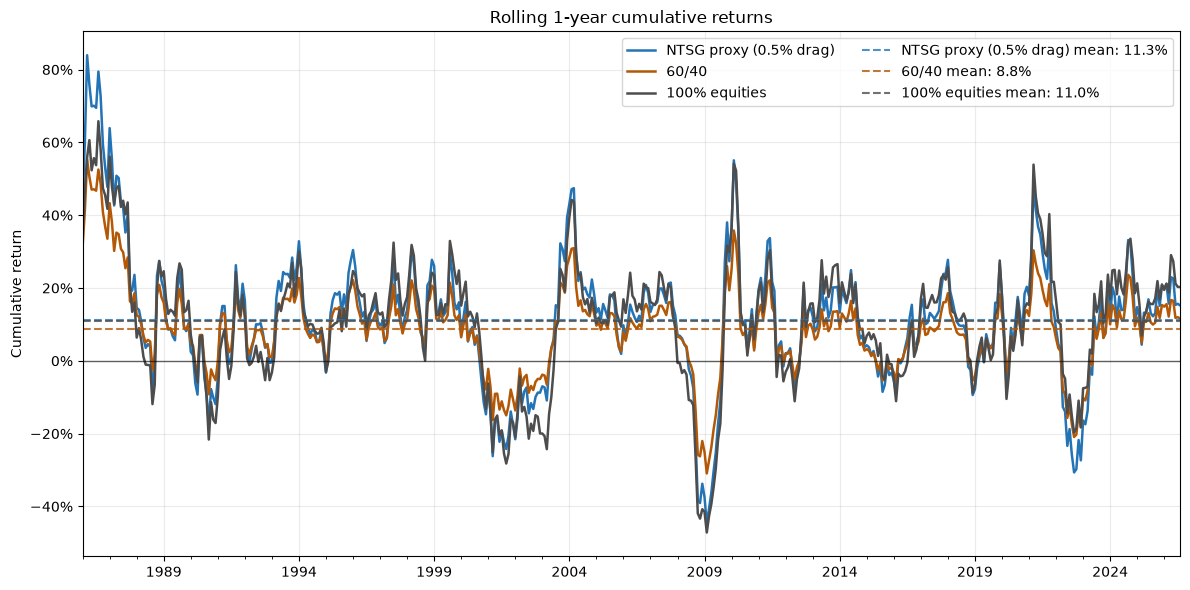

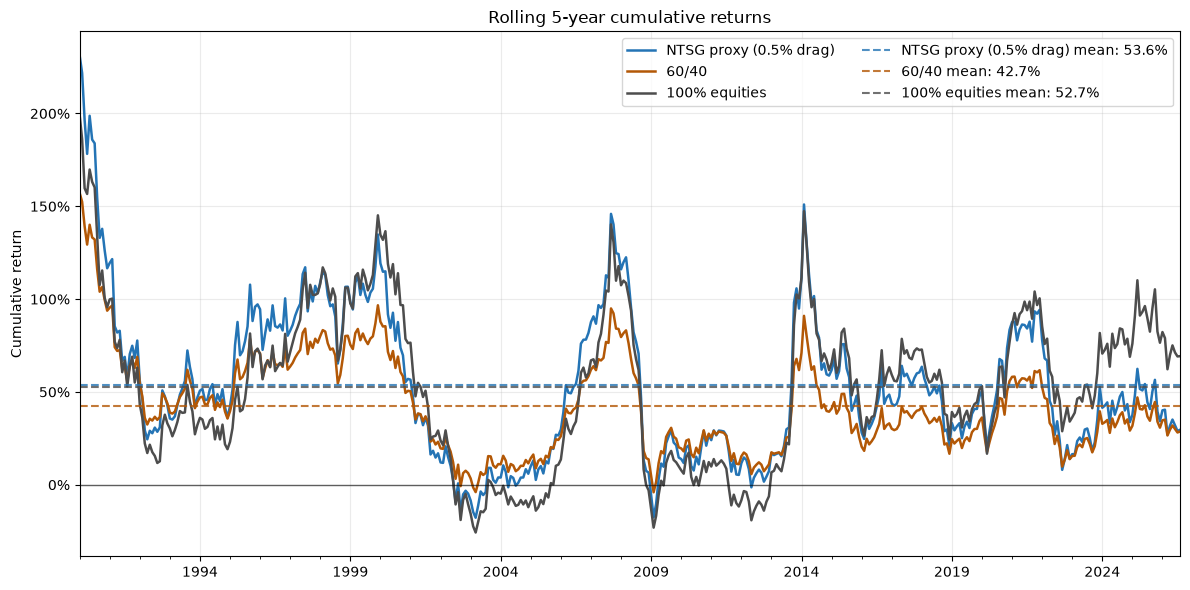

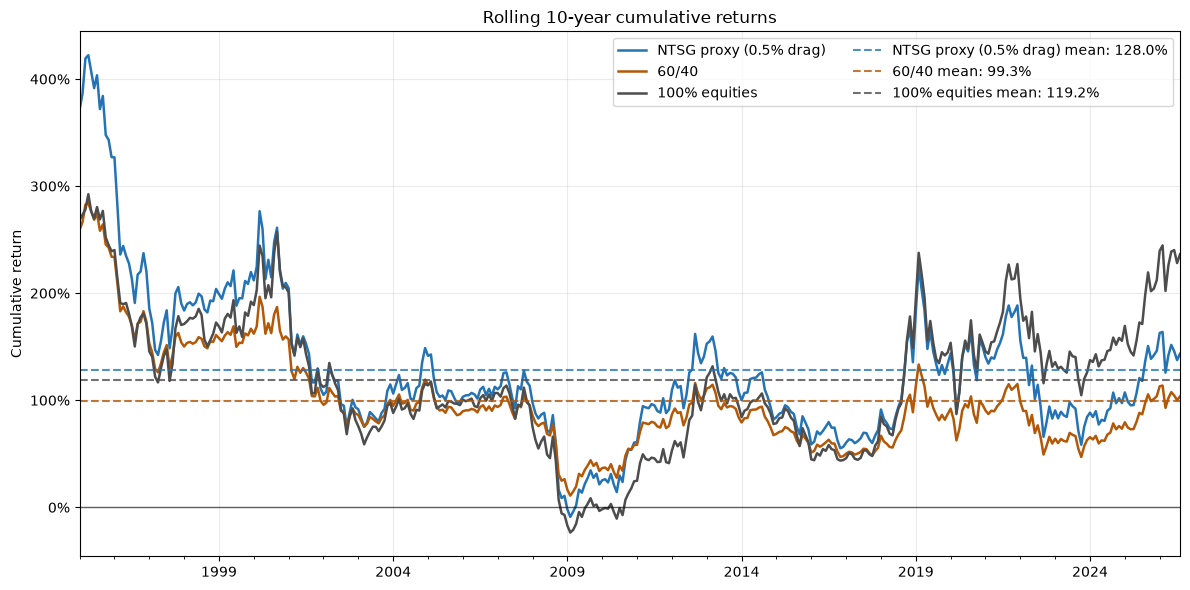

In [10]:
from matplotlib.ticker import PercentFormatter

rolling_portfolios = portfolio_returns[["NTSG proxy (0.5% drag)", "60/40", "100% equities"]]
for months in (12, 60, 120):
    rolling_returns = (1 + rolling_portfolios).rolling(months).apply(lambda x: x.prod() - 1, raw=True).dropna()
    ax = rolling_returns.plot(figsize=(12, 6), linewidth=1.8, color=[portfolio_colors[column] for column in rolling_returns],
                              style=[proxy_styles.get(column, "-") for column in rolling_returns])
    for line, column in zip(ax.lines, rolling_returns.columns):
        ax.axhline(rolling_returns[column].mean(), color=line.get_color(), linestyle="--", alpha=0.8,
                   label=f"{column} mean: {rolling_returns[column].mean():.1%}")
    ax.axhline(0, color="black", linewidth=1, alpha=0.6)
    ax.set_title(f"Rolling {months // 12}-year cumulative returns")
    ax.set_xlabel("")
    ax.set_ylabel("Cumulative return")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(alpha=0.25)
    ax.legend(ncol=2)
    plt.tight_layout()
    plt.show()


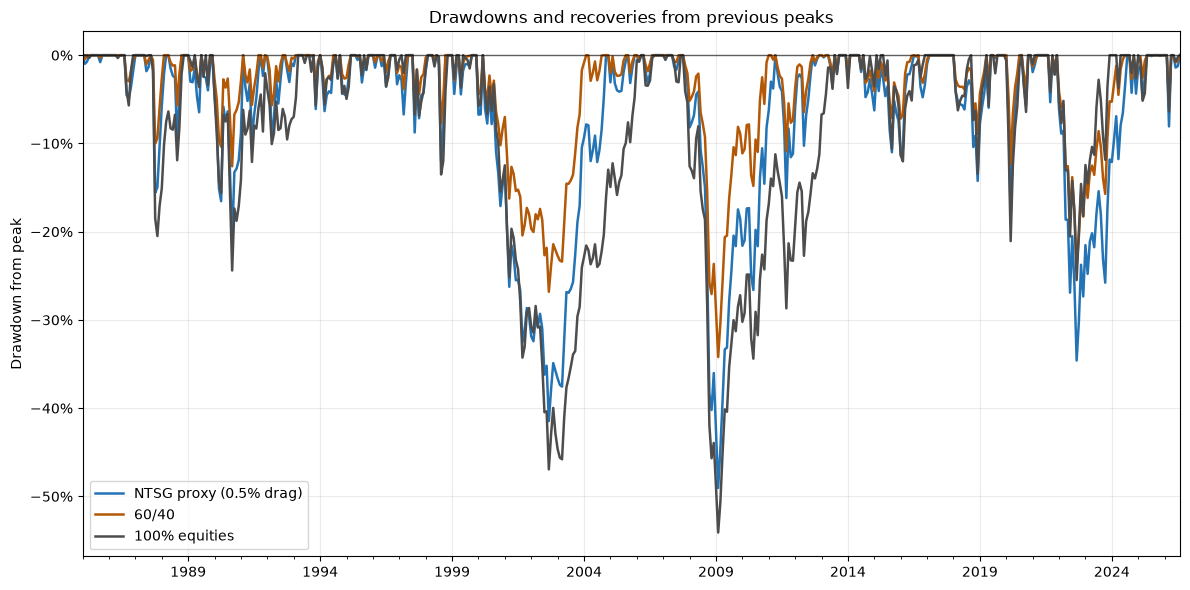

,Maximum drawdown,Peak,Trough,Recovery,Peak-to-recovery (months)
Portfolio,,,,,
NTSG proxy (0.5% drag),-49.05%,2007-10,2009-02,2011-04,42
60/40,-34.20%,2007-10,2009-02,2011-01,39
100% equities,-54.09%,2007-10,2009-02,2013-07,69


In [11]:
selected_portfolios = ["NTSG proxy (0.5% drag)", "60/40", "100% equities"]
selected_wealth = wealth_history[selected_portfolios]
drawdowns = selected_wealth / selected_wealth.cummax() - 1

ax = drawdowns.plot(figsize=(12, 6), linewidth=1.8,
                    color=[portfolio_colors[column] for column in selected_portfolios])
ax.axhline(0, color="black", linewidth=1, alpha=0.6)
ax.set_title("Drawdowns and recoveries from previous peaks")
ax.set_xlabel("")
ax.set_ylabel("Drawdown from peak")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

recovery_rows = []
for column in selected_portfolios:
    trough = drawdowns[column].idxmin()
    peak = selected_wealth.loc[:trough, column].idxmax()
    recovery = selected_wealth.loc[trough:, column]
    recovery = recovery[recovery >= selected_wealth.loc[peak, column]]
    recovery_date = recovery.index[0] if not recovery.empty else None
    months_to_recover = ((recovery_date.year - peak.year) * 12 + recovery_date.month - peak.month
                         if recovery_date is not None else None)
    recovery_rows.append({
        "Portfolio": column,
        "Maximum drawdown": f"{drawdowns.loc[trough, column]:.2%}",
        "Peak": peak.strftime("%Y-%m"),
        "Trough": trough.strftime("%Y-%m"),
        "Recovery": recovery_date.strftime("%Y-%m") if recovery_date is not None else "Not recovered",
        "Peak-to-recovery (months)": months_to_recover,
    })
display(pd.DataFrame(recovery_rows).set_index("Portfolio"))

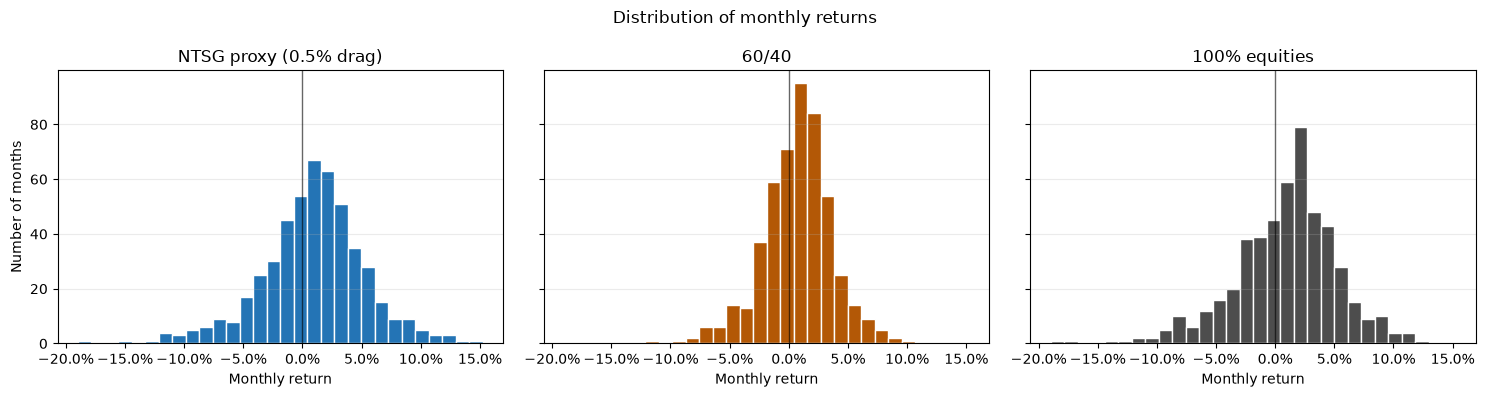

In [12]:
histogram_returns = portfolio_returns[selected_portfolios]
bins = np.linspace(histogram_returns.min().min(), histogram_returns.max().max(), 31)
fig, axes = plt.subplots(1, len(selected_portfolios), figsize=(15, 4), sharex=True, sharey=True)
for ax, column in zip(axes, selected_portfolios):
    ax.hist(histogram_returns[column], bins=bins, color=portfolio_colors[column], edgecolor="white")
    ax.axvline(0, color="black", linewidth=1, alpha=0.6)
    ax.set_title(column)
    ax.set_xlabel("Monthly return")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Number of months")
fig.suptitle("Distribution of monthly returns")
plt.tight_layout()
plt.show()

## Unhedged EUR comparison

The USD portfolios are translated using month-end USD per EUR spot rates, with no currency hedge. Before 1999, the EUR series uses the ECU as a historical proxy. Sharpe and Sortino use the USD bill return translated into EUR as the comparison return; it carries USD currency risk and is not a EUR risk-free rate.

Unhedged EUR returns: 1985-02 to 2026-08
Before 1999, EUR is represented by an ECU proxy; Sharpe and Sortino use USD bills translated to EUR, not EUR cash.
Average drawdown is the mean of each episode’s maximum loss, including ongoing episodes.


,Total return,CAGR,Volatility,Max drawdown,Average drawdown,Sharpe,Sortino,Calmar
NTSG proxy (0% drag),3710.59%,9.15%,13.31%,-45.51%,-5.87%,0.48,0.70,0.20
NTSG proxy (0.5% drag),3270.26%,8.83%,13.31%,-45.95%,-5.85%,0.46,0.67,0.19
NTSG proxy (1% drag),2880.53%,8.51%,13.32%,-46.39%,-5.91%,0.44,0.64,0.18
60/40,1610.12%,7.07%,9.66%,-35.79%,-4.81%,0.49,0.71,0.20
100% equities,2934.10%,8.55%,14.75%,-56.08%,-8.32%,0.46,0.66,0.15


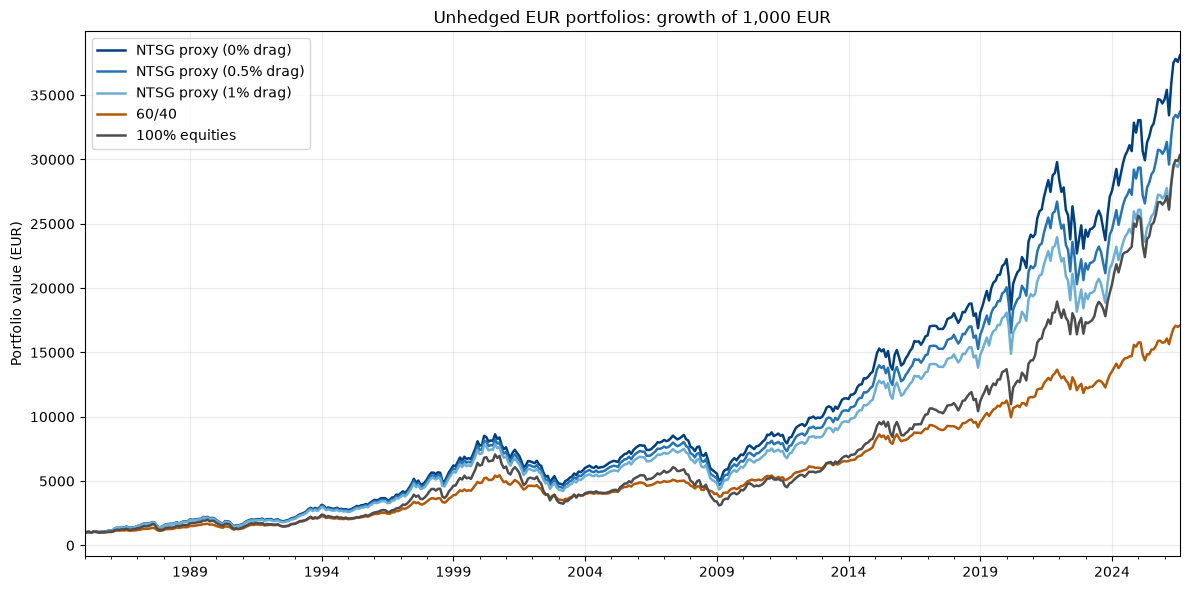

In [ ]:
eur_fx = load_prices("EURUSD_CURVO_MONTHLY.CSV")
eur_dates = portfolio_returns.index.insert(0, portfolio_returns.index[0] - pd.offsets.MonthEnd(1))
eur_fx = eur_fx.reindex(eur_dates)
if eur_fx.isna().any():
    raise ValueError("Missing monthly USD per EUR exchange rates in the portfolio history")
eur_fx_factor = (eur_fx.shift(1) / eur_fx).iloc[1:]
eur_returns = (1 + portfolio_returns).mul(eur_fx_factor, axis=0) - 1
eur_cash = (1 + returns["risk_free"]).mul(eur_fx_factor) - 1

eur_wealth = (1 + eur_returns).cumprod()
eur_wealth.loc[eur_dates[0]] = 1.0
eur_wealth = eur_wealth.sort_index()
eur_drawdowns = eur_wealth / eur_wealth.cummax() - 1
eur_max_drawdown = eur_drawdowns.min()
eur_average_drawdown = pd.Series({
    column: series[series < 0].groupby(series.eq(0).cumsum()).min().mean()
    for column, series in eur_drawdowns.items()
})
eur_total_return = eur_wealth.iloc[-1] - 1
eur_cagr = (1 + eur_total_return) ** (12 / len(eur_returns)) - 1
eur_volatility = eur_returns.std(ddof=1) * 12 ** 0.5
eur_excess = eur_returns.sub(eur_cash, axis=0)
eur_excess_volatility = eur_excess.std(ddof=1).replace(0, float("nan"))
eur_downside = (eur_excess.clip(upper=0).pow(2).mean() ** 0.5).replace(0, float("nan"))
eur_summary = pd.DataFrame({
    "Total return": eur_total_return,
    "CAGR": eur_cagr,
    "Volatility": eur_volatility,
    "Max drawdown": eur_max_drawdown,
    "Average drawdown": eur_average_drawdown,
    "Sharpe": eur_excess.mean() / eur_excess_volatility * 12 ** 0.5,
    "Sortino": eur_excess.mean() / eur_downside * 12 ** 0.5,
    "Calmar": eur_cagr / (-eur_max_drawdown).replace(0, float("nan")),
})
eur_formatted_summary = eur_summary.copy()
for column in ["Total return", "CAGR", "Volatility", "Max drawdown", "Average drawdown"]:
    eur_formatted_summary[column] = eur_summary[column].map(lambda x: f"{x:.2%}" if pd.notna(x) else "N/A")
for column in ["Sharpe", "Sortino", "Calmar"]:
    eur_formatted_summary[column] = eur_summary[column].map(lambda x: f"{x:.2f}" if pd.notna(x) else "N/A")
print(f"Unhedged EUR returns: {eur_returns.index[0]:%Y-%m} to {eur_returns.index[-1]:%Y-%m}")
print("Before 1999, EUR is represented by an ECU proxy; Sharpe and Sortino use USD bills translated to EUR, not EUR cash.")
print("Average drawdown is the mean of each episode’s maximum loss, including ongoing episodes.")
display(eur_formatted_summary)

ax = (1000 * eur_wealth).plot(figsize=(12, 6), linewidth=1.8,
                              color=[portfolio_colors[column] for column in eur_wealth],
                              style=[proxy_styles.get(column, "-") for column in eur_wealth])
ax.set_title("Unhedged EUR portfolios: growth of 1,000 EUR")
ax.set_xlabel("")
ax.set_ylabel("Portfolio value (EUR)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()